# Heartbeat-evoked potentials

Choose **single-subject demonstration** or **manuscript batch** in step 1.
Use the **Python (dbh)** kernel after the [environment setup](../README.md#setup).

- **Single subject:** use the current cleaned EEG, extracted ECG and reviewed
  R peaks from `01_preprocessing/outputs/demo/`. Demonstrate ECG alignment, ECG
  regression and clean HEP epoch extraction; save to `04_HEP/outputs/demo/`.
  No raw recording is read.
- **Manuscript batch:** read participants from the CSV and use the manuscript
  cleaned EEG and reviewed R peaks in `01_preprocessing/outputs/manuscript/` with
  the manuscript aligned ECG in `04_HEP/outputs/manuscript/`. Rebuild ECG-regressed
  EEG and HEP epochs in `04_HEP/outputs/batch/` (or an output folder you select).
  The manuscript inputs remain unchanged.

**HEP preprocessing: steps 2–3. Group analyses and figures: steps 4–7.**
Group analyses require all 148 children; after the demonstration, step 3 still
asks whether to run them from the manuscript or rebuilt batch averages.
MATLAB with EEGLAB/ERPLAB is needed for signal preparation. Using the supplied
manuscript averages for group analyses needs Python only.

| Step | What it does | Output |
|---|---|---|
| 1 | Select demonstration or manuscript batch; choose paths and cache use | Run settings and one log |
| 2 · HEP preprocessing | Regress ECG and extract clean R-locked epochs; align the extracted ECG first for the demonstration | ECG-regressed EEG and individual HEP epochs |
| 3 · HEP preprocessing | Inspect the demonstration; select/build the full-cohort averages for the group analyses | Retained-beat summary; ROI/channel averages |
| 4 · Group analysis | Compare movie conditions within age groups, regions and time windows | 54 temporal cluster tests |
| 5 · Group analysis | Summarise significant clusters and test age associations | Table S3a–b |
| 6 · Group analysis | Compute channel contrasts for the four scalp maps (no drawing) | Channel contrasts and map inputs |
| 7 · Figure | Draw or display the waveforms and the four scalp maps | Figure 3 (PNG) |

**Manuscript inputs:** the cleaned EEG, corrected R peaks, aligned ECG and
ROI/channel averages used for the submitted manuscript. Step 1 reports how many
selected EEG files are available; all four input kinds cover the 148 children.
EEG sample values are unchanged; duplicate FieldTrip signal copies and ICA
activation caches were omitted to save space. The manuscript averages are a
separate reference, not rebuilt batch output.

**Input versions are separate:** the demonstration uses the current preprocessing
example. The manuscript batch starts after the manuscript EEG cleaning and manual
R-peak review, so it does not rerun ICA or open the peak editor.


## 1. Select the workflow and paths

At each prompt, type a choice and press **Enter**. Enter alone selects the stated
default. No code edits are needed.

- **1 — single subject (default):** enter an ID (default `sub-001`). Complete
  [preprocessing](../01_preprocessing/run_preprocessing.ipynb) for that subject
  first (steps 3, 5 and 6: cleaned EEG, extracted ECG, reviewed R peaks).
  Step 3 then asks whether to continue to the group analyses.
- **2 — manuscript batch:** select the participant CSV and a batch output folder.
  Inputs always come from the manuscript folders.
  A complete rebuild requires tens of GB of additional space. You can enter an
  external output folder; step 2 checks space before starting.

For both workflows, also choose **1** to reuse complete cached statistics or **2** to
recompute statistics and figures. Steps 2 and 3 separately ask about signal
outputs and averages. Switching between manuscript and rebuilt averages checks
input hashes before reusing statistics.

MATLAB is located automatically (`MATLAB_EXE = None`). Paths below show exactly
what will be read and written. Relative input paths are resolved from the repository
root. Each run uses one log in `04_HEP/logs/`; rerunning this cell starts a new log.

| Input (read only) | Demonstration | Manuscript batch |
|---|---|---|
| Participants | `00_data/participants.csv` | selected CSV (default the same) |
| Cleaned EEG, reviewed R peaks | `01_preprocessing/outputs/demo/eeg/cleaned/`, `ecg/r_peaks/` | `01_preprocessing/outputs/manuscript/eeg/cleaned/`, `ecg/r_peaks/` |
| ECG | `01_preprocessing/outputs/demo/ecg/extracted/` (aligned in step 2) | `04_HEP/outputs/manuscript/ecg_trimmed/` |
| Reference averages | not used | `04_HEP/outputs/manuscript/averages/` |

| Intermediate output | Location |
|---|---|
| Step 2: aligned ECG (demonstration), ECG-regressed EEG, clean HEP epochs | `outputs/demo/` or the batch output folder |
| Step 3: rebuilt ROI/channel averages (batch) | `<batch output>/averages/` |
| Steps 4–6: cluster tests, cluster means, scalp-map inputs | `04_HEP/cache/` (supplied with the submitted-analysis results; replaced when recomputed) |
| Final: Figure 3 PNGs and Table S3a–b | `results/Main/`, `results/SI/` |


In [3]:
from dataclasses import replace
from importlib import import_module, reload
from pathlib import Path
import os
import sys

import matplotlib as mpl
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, Markdown, display

override = os.environ.get("HEP_PROJECT_ROOT")
candidates = [Path(override).expanduser()] if override else [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p.resolve() for p in candidates if (p / "04_HEP/config/hep_config.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the repository, or set HEP_PROJECT_ROOT.")

HEP = ROOT / "04_HEP"
INFO_FILE = ROOT / "00_data/participants.csv"
OUTPUT_ROOT = Path(os.environ.get("HEP_OUTPUT_ROOT", str(HEP))).expanduser()
if not OUTPUT_ROOT.is_absolute():
    OUTPUT_ROOT = ROOT / OUTPUT_ROOT
OUTPUT_ROOT = OUTPUT_ROOT.resolve()
MATLAB_EXE = None

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RunLog = reload(import_module("common.run_log")).RunLog
cache_policy = reload(import_module("common.cache_policy"))
settings = reload(import_module("04_HEP.config.hep_config"))
inputs = reload(import_module("04_HEP.analysis.inputs"))
reload(import_module("04_HEP.config.notebook_helpers"))
reload(import_module("04_HEP.preparation.check_hep_inputs"))
preparation = reload(import_module("04_HEP.config.epoch_preparation"))
test_waveforms = reload(import_module("04_HEP.analysis.analyze_hep_waveforms")).run_analysis
test_age_effects = reload(import_module("04_HEP.analysis.analyze_hep_age_effects")).run_analysis
prepare_maps = reload(import_module("04_HEP.analysis.prepare_hep_topographies")).run_analysis
draw_waveforms = reload(import_module("04_HEP.plotting.plot_hep_waveforms")).plot_waveforms
scalp_plots = reload(import_module("04_HEP.plotting.plot_hep_cluster_topographies"))
draw_figure_3 = reload(import_module("04_HEP.plotting.plot_figure_3_hep")).plot_figure

LOG = RunLog(OUTPUT_ROOT / "logs", ROOT, title="HEP", announce=False)
display(HTML('<style id="dbh-notebook-style">' +
             (ROOT / "common/notebook_style.css").read_text(encoding="utf-8") + "</style>"))
WORKFLOW, PREPARATION_IDS, PREPARATION_PATHS, SIGNAL_OUTPUT = preparation.choose_workflow(
    ROOT, OUTPUT_ROOT, log=LOG,
)
BATCH_OUTPUT = SIGNAL_OUTPUT if WORKFLOW == "batch" else OUTPUT_ROOT / "outputs/batch"
MANUSCRIPT_PATHS = settings.make_paths(
    root=ROOT, participants=INFO_FILE, epochs_dir=BATCH_OUTPUT / "hep_epochs_ecgreg",
    output_root=OUTPUT_ROOT,
)
BATCH_PATHS = replace(
    MANUSCRIPT_PATHS, roi=BATCH_OUTPUT / "averages/roi_waves_ecgreg.mat",
    channel_dir=BATCH_OUTPUT / "averages",
)
PATHS = MANUSCRIPT_PATHS
RESULT_DIR, TOPO_DIR = PATHS.results, PATHS.topographies
FIGURE_DIR, TABLE_DIR = PATHS.figures, PATHS.tables
RECOMPUTE = cache_policy.choose_recompute(heading="Steps 4–7: statistical analyses and figures",
                                          note="Choose 2 after changing the input data or analysis settings. "
                                               "Step 2 separately asks about signal preparation; step 3 asks about averages.")
UPDATED_STEPS = set()
PREPARED_IDS = []
COHORT_READY = WORKFLOW == "batch"  # Steps 1 and 7 can display the manuscript figure.
LOG.write("Statistics: recompute" if RECOMPUTE else "Statistics: reuse complete matching cache")
print("Run log:", LOG.display(LOG.path))


1 = single-subject demonstration using current preprocessing outputs (default)
2 = batch from the manuscript cleaned EEG, reviewed R peaks and aligned ECG


Type 1 or 2, then press Enter (Enter alone = 1):  1
Subject ID (Enter alone = sub-001):  sub-001



Workflow: single-subject demonstration (sub-001)
Inputs (read only)
  Cleaned EEG       01_preprocessing/outputs/demo/eeg/cleaned
  Extracted ECG     01_preprocessing/outputs/demo/ecg/extracted
  Reviewed R peaks  01_preprocessing/outputs/demo/ecg/r_peaks
Outputs
  Aligned ECG       04_HEP/outputs/demo/ecg_trimmed
  ECG-regressed EEG 04_HEP/outputs/demo/preprocessed_ecgreg
  Clean HEP epochs  04_HEP/outputs/demo/hep_epochs_ecgreg
Steps 4–7: statistical analyses and figures
1 = use complete saved results; compute missing or outdated steps (default)
2 = recompute and replace saved results and figures
Choose 2 after changing the input data or analysis settings. Step 2 separately asks about signal preparation; step 3 asks about averages.


Type 1 or 2, then press Enter (Enter alone = 1):  2


Run log: 04_HEP/logs/20261030_224641.log


## 2. Prepare ECG-regressed EEG and clean HEP epochs

Choose **1** to skip, **2** to prepare missing files (default), or **3** to
recompute and replace the selected workflow's signal outputs. Existing manuscript
inputs and the other workflow's outputs are kept.

**Manuscript batch:** use the manuscript aligned ECG with the manuscript cleaned EEG
and reviewed R peaks. **Demonstration:** first filter the extracted full-recording ECG
at 0.1–45 Hz and cut it to the current cleaned EEG segments (aligned ECG).

Both then perform the same HEP steps:

1. Regress ECG and its derivative from each EEG channel. Estimate coefficients
   from 1-Hz high-passed copies and apply them to the main 0.1–45-Hz data.
2. Low-pass to 30 Hz; extract R-locked epochs from −200 to 600 ms; baseline-correct
   from −200 to 0 ms. Apply 150-µV amplitude and peak-to-peak thresholds,
   interpolate at most 13 bad channels per epoch, and discard remaining bad epochs.
   The saved time grid is −200 to 598 ms at 500 Hz.

The batch follows the CSV order. Missing source files print `Missing` and are
skipped. Option 2 reuses existing complete epochs, and an existing ECG-regressed
EEG file is reused for its epoch extraction; only option 3 regenerates both.
Incomplete or unreadable files are regenerated. A fresh batch rebuild can take a
long time; processing progress appears below.

| Intermediate file | Location |
|---|---|
| `{ID}_ecg_trimmed.npz` | Batch reads `outputs/manuscript/ecg_trimmed/`; demonstration writes `outputs/demo/ecg_trimmed/` |
| `{ID}_continuous_clean_ecg_regressed.mat` | `<selected output>/preprocessed_ecgreg/` |
| `{ID}_hep_epochs.mat` | `<selected output>/hep_epochs_ecgreg/` |

The default selected output is `04_HEP/outputs/batch/` or `04_HEP/outputs/demo/`.
The prompt in step 1 can change the batch output location.


In [5]:
PREPARED_IDS = []
with LOG.step("HEP signal preparation"):
    SIGNAL_MODE = preparation.choose_epoch_mode(log=LOG)
    if SIGNAL_MODE == "skip":
        preparation.report("Skipped by choice; no signal files were generated.", LOG)
    else:
        jobs = preparation.plan_epoch_preparation(
            PREPARATION_IDS, PREPARATION_PATHS, rebuild=SIGNAL_MODE == "recompute",
            align_missing=WORKFLOW == "demo", log=LOG,
        )
        if preparation.enough_output_space(jobs, PREPARATION_PATHS, LOG, root=ROOT):
            options = dict(root=ROOT, output_root=OUTPUT_ROOT, log=LOG)
            if WORKFLOW == "demo":
                preparation.run_alignment(jobs["align"], PREPARATION_PATHS, **options)
            preparation.run_matlab_preparation(
                "regress_ecg_from_eeg", jobs["regress"], PREPARATION_PATHS,
                executable=MATLAB_EXE, **options,
            )
            preparation.run_matlab_preparation(
                "extract_hep_epochs", jobs["epochs"], PREPARATION_PATHS,
                executable=MATLAB_EXE, **options,
            )
            PREPARED_IDS = jobs["epochs"]



Step 2: prepare clean HEP epochs
1 = skip signal preparation; use existing epochs or averages
2 = prepare missing epochs; keep existing signal outputs (default)
3 = recompute and replace signal outputs for selected subjects


Type 1, 2 or 3, then press Enter (Enter alone = 2):  3


Signal preparation mode: recompute
Existing epochs: 0; to prepare: 1; Missing: 0
Aligned ECG 1/1: sub-001, 307671 samples
Saved: 04_HEP/outputs/demo/ecg_trimmed
you rename the function to avoid a potential name conflict. 
you rename the function to avoid a potential name conflict. 

==========  ECG-REGRESS  |  sub-001  ==========
[summary] sub-001 ECG regression: 63 channels, 307671 samples; ECG and derivative with intercept; coefficients estimated at 1 Hz high-pass
R2 median 0.000 (max 0.006) | QRS residual ratio median 0.97 | 7.7s
  -> 04_HEP/outputs/demo/preprocessed_ecgreg/sub-001_continuous_clean_ecg_regressed.mat
DBH_HEP_STEP_COMPLETE
you rename the function to avoid a potential name conflict. 
you rename the function to avoid a potential name conflict. 

Path Warning: It appears that you have added the path to all of the
subfolders to EEGLAB. This may create issues with some EEGLAB extensions
If EEGLAB cannot start or your experience a large number of warning
messages, remove al

# 3. Inspect the demonstration or select cohort averages

**Single subject:** display retained beats by condition and the clean epoch file
location. The demonstration itself ends here; the prompt below then offers the
group analyses with option 4 (finish) as the default.

**Both workflows:** select the group-analysis input explicitly:

- **1 — rebuilt batch averages (batch default):** use averages in the batch
  output folder (`outputs/batch/` unless chosen otherwise in step 1), creating
  them from all 148 epoch files if missing. Newer epochs refresh these averages.
- **2 — replace batch averages:** recompute both average files from all 148 epoch files.
- **3 — supplied manuscript averages:** read the 148-child manuscript averages in
  `outputs/manuscript/averages/`. This works without rebuilding epochs.
- **4 — finish (demonstration default):** skip the group analyses.

Missing epochs prevent incomplete cohort aggregation; their count is shown and
you can choose option 3 or 4. New averages are validated before replacing batch
averages. The manuscript reference is never overwritten.

| Intermediate file | Contents |
|---|---|
| `averages/roi_waves_ecgreg.mat` | Each child's retained-epoch mean by region and movie |
| `averages/chan_means.npz` | Each child's retained-epoch mean for all 63 channels by movie |
| `averages/export_manifest.json` | Input files, hashes and export settings |

New averages go into the **selected batch output folder**. Individual epochs stay
in its `hep_epochs_ecgreg/` folder. This step checks 148 IDs, ages, counts, the
400-sample time grid, and agreement between channel and ROI means. It also reports
agreement with the manuscript channel means when using rebuilt averages.
If retained-trial counts or waveforms differ (beyond 0.00001 µV numerical tolerance),
the rebuilt files are retained for inspection and group analyses are skipped.
Choose option 3 to use the unchanged manuscript reference.

The input summary appears below. `participants`, `roi_waveforms`, `channel_means`
and `retained_trials` remain available for batch inspection.


In [7]:
COHORT_READY = False
with LOG.step("HEP outputs and cohort averages"):
    if WORKFLOW == "demo":
        summary = preparation.epoch_summary(PREPARATION_IDS, PREPARATION_PATHS, LOG, root=ROOT)
        if summary:
            display(pd.DataFrame(summary).style.hide(axis="index"))
        choice = preparation.choose_average_source(MANUSCRIPT_PATHS, BATCH_PATHS, log=LOG, demo=True)
    else:
        choice = preparation.choose_average_source(
            MANUSCRIPT_PATHS, BATCH_PATHS, updated_epochs=PREPARED_IDS, log=LOG,
        )
    if choice is not None:
        PATHS, RECOMPUTE_AVERAGES = choice
        LOG.command([sys.executable, ROOT / "check_setup.py", "--python-only", "--quiet"])
        needs_aggregation = RECOMPUTE_AVERAGES
        reference_matches = True
        if PATHS == MANUSCRIPT_PATHS:
            checked_inputs = import_module("04_HEP.preparation.check_hep_inputs").check_inputs(PATHS)
        else:
            checked_inputs = preparation.prepare_aggregates(
                PATHS, recompute=RECOMPUTE_AVERAGES, executable=MATLAB_EXE, log=LOG,
            )
            reference_matches = preparation.compare_manuscript_averages(PATHS, MANUSCRIPT_PATHS, LOG)
        participants = checked_inputs["participants"]
        roi_data, times, subject_ids, age_groups, roi_waveforms = checked_inputs["roi"]
        channel_times, positions, channel_ids, channel_labels, channel_means, _, roi_masks, export = checked_inputs["channels"]
        retained_trials = roi_data["n_trials"]
        age_counts = {group: int((age_groups == group).sum()) for group in settings.GROUPS}
        input_summary = pd.DataFrame([
            {"Input": "Participants", "Available": len(participants)},
            {"Input": "Age groups (5–6 / 7–8 / 9–10 years)",
             "Available": " / ".join(str(n) for n in age_counts.values())},
            {"Input": "ROI waveforms", "Available": "3 regions × 3 movies × 148 children × 400 samples"},
            {"Input": "Scalp channels", "Available": len(channel_labels)},
            {"Input": "Time grid", "Available": f"{times[0]:.0f} to {times[-1]:.0f} ms, 2-ms steps"},
            {"Input": "Retained beats per child/movie", "Available": f"{retained_trials.min():.0f}–{retained_trials.max():.0f}"},
        ])
        display(input_summary.style.hide(axis="index"))
        if needs_aggregation and reference_matches:
            UPDATED_STEPS.update({"clusters", "age", "maps", "waveforms", "scalp figures"})
        LOG.write(f"Inputs passed: {len(participants)} children, {len(channel_labels)} channels, {len(times)} samples; age groups {age_counts}")
        COHORT_READY = reference_matches
        if not reference_matches:
            preparation.report(
                "Group analyses skipped: rebuilt averages differ from the manuscript reference. "
                "Check the source versions, or rerun step 3 and choose 3 for the manuscript averages.", LOG,
            )


sub-001: retained beats {'fear': 271, 'neutral': 355, 'happy': 258}; epochs saved to 04_HEP/outputs/demo/hep_epochs_ecgreg/sub-001_hep_epochs.mat


ID,fear,neutral,happy,Clean epochs
sub-001,271,355,258,04_HEP/outputs/demo/hep_epochs_ecgreg/sub-001_hep_epochs.mat



Group analyses (steps 4-7) are optional after the demonstration.

Manuscript averages (read only)
  ROI averages      04_HEP/outputs/manuscript/averages/roi_waves_ecgreg.mat  [found, 3.9 MB]
  Channel averages  04_HEP/outputs/manuscript/averages/chan_means.npz  [found, 39.6 MB]
Rebuilt batch averages
  ROI averages      04_HEP/outputs/batch/averages/roi_waves_ecgreg.mat  [missing]
  Channel averages  04_HEP/outputs/batch/averages/chan_means.npz  [missing]
Batch epochs: 1/148 in 04_HEP/outputs/batch/hep_epochs_ecgreg
1 = use rebuilt batch averages; create them if missing
2 = recompute and replace batch averages from all 148 epoch files
3 = use the supplied manuscript averages for group analyses
4 = finish without group analyses (default)


Type 1–4, then press Enter (Enter alone = 4):  1


Missing: 147 epoch files; cannot generate full-cohort averages. Existing files are unchanged.
First missing IDs: sub-002, sub-003, sub-004, sub-005, sub-006
Choose 3 for the manuscript averages or 4 to finish.


Type 1–4, then press Enter (Enter alone = 4):  2


Missing: 147 epoch files; cannot generate full-cohort averages. Existing files are unchanged.
First missing IDs: sub-002, sub-003, sub-004, sub-005, sub-006
Choose 3 for the manuscript averages or 4 to finish.


Type 1–4, then press Enter (Enter alone = 4):  3


Group inputs: supplied manuscript averages (unchanged).
Python 3.12.7: /opt/anaconda3/envs/dbh/bin/python
[OK] numpy 2.2.6; scipy 1.16.3; pandas 2.3.3; matplotlib 3.10.8; sklearn 1.8.0; statsmodels 0.14.6; h5py 3.16.0; joblib 1.4.2; numba 0.61.2; llvmlite 0.44.0; tqdm 4.66.5; mne 1.11.0; neurokit2 0.2.13; IPython 9.17.1; ipykernel 6.28.0; jupyterlab 4.2.5; nbformat 5.10.4; tkinter available
Loaded ROI averages: 04_HEP/outputs/manuscript/averages/roi_waves_ecgreg.mat
Loaded channel averages: 04_HEP/outputs/manuscript/averages/chan_means.npz
Input validation passed.


Input,Available
Participants,148
Age groups (5–6 / 7–8 / 9–10 years),50 / 49 / 49
ROI waveforms,3 regions × 3 movies × 148 children × 400 samples
Scalp channels,63
Time grid,"-200 to 598 ms, 2-ms steps"
Retained beats per child/movie,177–515


## 4. Compute or load the temporal cluster tests

Run **54 paired tests**: 3 age groups × 3 regions × 3 movie contrasts × 2 windows.
Each test uses **10,000 subject-wise sign flips**, resetting seed 0. Same-sign
clusters need at least 10 samples (20 ms), with a two-sided cluster-forming
threshold of 0.05 and a maximum absolute cluster-mass null distribution.

The 100–300 and 300–500 ms windows both include 300 ms. Cluster correction is
within each test. This is the longest step; progress is shown by group and region.

Display significant clusters below. `temporal_clusters` and its saved CSV contain
all candidate clusters, with inclusive endpoints and a `survives` flag for p < .05.
If this step is recomputed, the dependent tables, maps and figures are refreshed.

**Intermediate files — saved on computation, read on reuse:**

- `04_HEP/cache/condition_within_group_ecgreg_final.csv`: all candidate clusters,
  their intervals, cluster masses, corrected p-values and significance flags.
- `04_HEP/cache/waveforms_manifest.json`: analysis settings and input-file record.


In [9]:
if not COHORT_READY:
    print("Skipped: cohort analysis was not selected or validated in step 3.")
else:
    with LOG.step("54 temporal cluster tests"):
        if cache_policy.use_cached_results(
            [PATHS.clusters, RESULT_DIR / "waveforms_manifest.json"],
            recompute=RECOMPUTE or "clusters" in UPDATED_STEPS, label="HEP clusters", log=LOG,
            inputs=[PATHS.participants, PATHS.roi],
            manifest=RESULT_DIR / "waveforms_manifest.json",
        ):
            temporal_clusters = inputs.load_clusters(PATHS)
        else:
            LOG.write(
                f"Parameters: 54 tests; {settings.N_PERM} sign flips each; seed {settings.SEED}; "
                f"alpha {settings.ALPHA}; minimum {settings.MIN_MS} ms; inclusive windows {settings.WINDOWS}"
            )
            temporal_clusters = test_waveforms(PATHS, print_tables=False)
            UPDATED_STEPS.update({"age", "maps", "waveforms", "scalp figures"})
            UPDATED_STEPS.discard("clusters")
        significant_clusters = temporal_clusters.loc[temporal_clusters["survives"]]
        print(f"Significant clusters: {len(significant_clusters)} / {len(temporal_clusters)} candidates")
        display(significant_clusters[["group", "region", "pair", "window", "t_start", "t_end", "p", "dz"]]
                .style.hide(axis="index").format({"t_start": "{:.0f}", "t_end": "{:.0f}", "p": "{:.4f}", "dz": "{:.2f}"}))
        LOG.write(f"Clusters: {len(temporal_clusters)} candidates, {len(significant_clusters)} significant; {PATHS.clusters}")


HEP clusters: recomputing and replacing saved results.
5-6, Frontal: six tests with 10,000 sign flips each
5-6, Central: six tests with 10,000 sign flips each
5-6, Posterior: six tests with 10,000 sign flips each
7-8, Frontal: six tests with 10,000 sign flips each
7-8, Central: six tests with 10,000 sign flips each
7-8, Posterior: six tests with 10,000 sign flips each
9-10, Frontal: six tests with 10,000 sign flips each
9-10, Central: six tests with 10,000 sign flips each
9-10, Posterior: six tests with 10,000 sign flips each
Saved: 04_HEP/cache/condition_within_group_ecgreg_final.csv
Significant clusters: 5 / 16 candidates


group,region,pair,window,t_start,t_end,p,dz
5-6,Frontal,happy - neutral,100-300,198,300,0.0095,0.38
5-6,Frontal,happy - neutral,300-500,300,412,0.0089,0.39
5-6,Central,fear - neutral,300-500,318,408,0.0136,-0.46
5-6,Posterior,fear - happy,300-500,300,364,0.0396,0.35
7-8,Central,fear - happy,100-300,100,178,0.0236,0.37


## 5. Compute or load Table S3 and age regressions

**Table S3a** describes the five reported significant clusters. For **Table S3b**,
average each child's paired regional contrast over each cluster's inclusive
time range, then regress this mean on age in months across all 148 children.
Slopes and standard errors are expressed per year; BH-FDR covers the five age tests.

Display both tables and save them to `results/SI/`. `table_s3a`, `table_s3b` and
`subject_cluster_means` remain available. The full age table also contains
descriptive within-group correlations, which are affected by cluster selection.

**Intermediate files — saved on computation, read on reuse:**

- `04_HEP/cache/hep_subject_cluster_means.csv`: each child's mean condition
  contrast within each reported cluster, used for the age regressions.
- `04_HEP/cache/age_effects_manifest.json`: regression settings and input-file record.

**Final tables:** `results/SI/Table_S3a_hep_clusters.csv` and
`results/SI/Table_S3b_hep_age_regression.csv`.


In [11]:
if not COHORT_READY:
    print("Skipped: cohort analysis was not selected or validated in step 3.")
else:
    with LOG.step("Table S3 and age effects"):
        table_a_file = TABLE_DIR / "Table_S3a_hep_clusters.csv"
        table_b_file = TABLE_DIR / "Table_S3b_hep_age_regression.csv"
        subject_file = RESULT_DIR / "hep_subject_cluster_means.csv"
        if cache_policy.use_cached_results(
            [table_a_file, table_b_file, subject_file, RESULT_DIR / "age_effects_manifest.json"],
            recompute=RECOMPUTE or "age" in UPDATED_STEPS,
            inputs=[PATHS.clusters, PATHS.participants, PATHS.roi],
            manifest=RESULT_DIR / "age_effects_manifest.json",
            label="Table S3", log=LOG,
        ):
            table_s3a, table_s3b = pd.read_csv(table_a_file), pd.read_csv(table_b_file)
        else:
            LOG.write("Parameters: five cluster means; age OLS across 148 children; coefficients per year; BH-FDR across five age tests")
            table_s3a, table_s3b = test_age_effects(PATHS, print_tables=False)
            UPDATED_STEPS.discard("age")
        subject_cluster_means = pd.read_csv(subject_file)
        display(Markdown("**Table S3a. Significant HEP clusters**"))
        display(table_s3a.style.hide(axis="index").format({
            "Cluster mass (sum t)": "{:.1f}", "Cluster p": "{:.3f}", "dz": "{:.2f}",
        }))
        display(Markdown("**Table S3b. Age associations across all children**"))
        display(table_s3b[["Age group (cluster)", "Region", "Contrast", "Cluster (ms)", "n", "β (µV/year)", "SE", "r", "p", "pFDR"]]
                .style.hide(axis="index").format({"β (µV/year)": "{:.3f}", "SE": "{:.3f}", "r": "{:.3f}", "p": "{:.3g}", "pFDR": "{:.3g}"}))
        LOG.write(f"Tables: {len(table_s3a)} clusters and {len(table_s3b)} age regressions; {TABLE_DIR}")


Table S3: recomputing and replacing saved results.


**Table S3a. Significant HEP clusters**

Age group,Region,Contrast,Window (ms),Cluster (ms),Cluster mass (sum t),Cluster p,dz
5-6,Frontal,Happy − Neutral,100-300,198–300,127.5,0.009,0.38
5-6,Frontal,Happy − Neutral,300-500,300–412,142.3,0.009,0.39
5-6,Central,Fear − Neutral,300-500,318–408,-139.7,0.014,-0.46
5-6,Posterior,Fear − Happy,300-500,300–364,77.0,0.040,0.35
7-8,Central,Fear − Happy,100-300,100–178,97.1,0.024,0.37


**Table S3b. Age associations across all children**

Age group (cluster),Region,Contrast,Cluster (ms),n,β (µV/year),SE,r,p,pFDR
5-6,Frontal,Happy − Neutral,198–300,148,-0.038,0.047,-0.067,0.421,0.491
5-6,Frontal,Happy − Neutral,300–412,148,-0.066,0.051,-0.106,0.201,0.491
5-6,Central,Fear − Neutral,318–408,148,0.018,0.023,0.064,0.439,0.491
5-6,Posterior,Fear − Happy,300–364,148,-0.041,0.048,-0.070,0.396,0.491
7-8,Central,Fear − Happy,100–178,148,-0.013,0.019,-0.057,0.491,0.491


## 6. Compute or load the channel contrasts for the four scalp maps

The two adjacent frontal happy-minus-neutral clusters in 5–6-year-olds share
one 198–412 ms display map: 108 unique samples, counting 300 ms once. Their
statistical tests remain separate. The other three maps use their original intervals.

Retain all 63 channels and average the paired condition differences within each
map's age group and interval. No new statistical tests are performed. This step
uses the five reported clusters and checks their expected display intervals.

Display the four-map summary table. The maps themselves are drawn in step 7.
`channel_results` and `subject_channel_results` remain available for inspection.

**Intermediate files — saved on computation, read on reuse:**

| File under `04_HEP/cache/topographies/` | Contents |
|---|---|
| `temporal_cluster_channel_means_final.csv` | Group-average condition contrasts for each map and channel |
| `temporal_cluster_subject_channel_means_final.csv` | Individual children's condition contrasts for each map and channel |
| `temporal_cluster_map_inputs.npz` | Map values, channel positions and labels needed to draw the four scalp maps |

`04_HEP/cache/topographies_manifest.json` records settings and source files.


In [13]:
if not COHORT_READY:
    print("Skipped: cohort analysis was not selected or validated in step 3.")
else:
    with LOG.step("Scalp map inputs"):
        channel_file = TOPO_DIR / "temporal_cluster_channel_means_final.csv"
        subject_channel_file = TOPO_DIR / "temporal_cluster_subject_channel_means_final.csv"
        if cache_policy.use_cached_results(
            [channel_file, subject_channel_file, TOPO_DIR / "temporal_cluster_map_inputs.npz",
             RESULT_DIR / "topographies_manifest.json"],
            recompute=RECOMPUTE or "maps" in UPDATED_STEPS,
            inputs=[PATHS.participants, PATHS.roi, PATHS.clusters, PATHS.channel_dir / "chan_means.npz"],
            manifest=RESULT_DIR / "topographies_manifest.json",
            label="Scalp maps", log=LOG,
        ):
            channel_results = pd.read_csv(channel_file)
            subject_channel_results = pd.read_csv(subject_channel_file)
        else:
            LOG.write("Parameters: four maps; all 63 channels; frontal union 198–412 ms, 108 unique samples; no additional tests")
            channel_results, subject_channel_results = prepare_maps(PATHS, print_tables=False)
            UPDATED_STEPS.add("scalp figures")
            UPDATED_STEPS.discard("maps")
        map_summary = channel_results.drop_duplicates("cluster_id")
        display(map_summary[["group", "region", "pair", "t_start", "t_end", "n_subjects", "n_time_samples"]]
                .style.hide(axis="index").format({"t_start": "{:.0f}", "t_end": "{:.0f}"}))
        LOG.write(f"Scalp maps: {len(map_summary)} maps; {TOPO_DIR}")


Scalp maps: recomputing and replacing saved results.


04_HEP/analysis/prepare_hep_topographies.py:124: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  channel_means = pd.concat(channel_tables, ignore_index=True)
04_HEP/analysis/prepare_hep_topographies.py:125: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  subject_means = pd.concat(subject_tables, ignore_index=True)


group,region,pair,t_start,t_end,n_subjects,n_time_samples
5-6,Frontal,happy - neutral,198,412,50,108
5-6,Central,fear - neutral,318,408,50,46
5-6,Posterior,fear - happy,300,364,50,33
7-8,Central,fear - happy,100,178,49,40


## 7. Draw or display the complete Figure 3

Combine the nine regional waveform panels with four scalp insets: three regions
at ages 5–6 and the central region at ages 7–8. A shared colour bar shows the
condition differences in µV. Rectangles identify the regions used in the waveform
analysis; they do not mark individually significant electrodes. Waveform shading
shows ±1 SEM.

Mode 1 displays up-to-date figures; missing outputs or newer plotting inputs
trigger redrawing. Mode 2 redraws and replaces them. The complete figure is
displayed below and saved as **Figure_3_hep.png** in
`results/Main/`. Individual panel PNGs remain available in the same folder:
`Figure_3_waveforms.png` and four `Figure_3_topography_*.png` files.

**Plotting record:** drawing the scalp panels also saves
`04_HEP/cache/topographies/temporal_cluster_map_manifest_final.json`, recording
their inputs, colour scale and PNG files. This step creates figures and this
record; it does not generate EEG signals or HEP epochs.

For the supplied manuscript figure only, choose batch in step 1 and run step 7.
To plot rebuilt batch averages, run step 3 before step 7. The participant table, ROI averages,
cluster CSV and prepared map inputs must already be available when redrawing.


HEP waveform figure: recomputing and replacing saved results.
Saved: results/Main/Figure_3_waveforms.png
HEP scalp figures: recomputing and replacing saved results.
Saved: results/Main/Figure_3_topography_5-6_frontal_happy-neutral_198-412ms.png
Saved: results/Main/Figure_3_topography_5-6_central_fearful-neutral_318-408ms.png
Saved: results/Main/Figure_3_topography_5-6_posterior_fearful-happy_300-364ms.png
Saved: results/Main/Figure_3_topography_7-8_central_fearful-happy_100-178ms.png
Complete Figure 3: recomputing and replacing saved results.
Saved: results/Main/Figure_3_hep.png


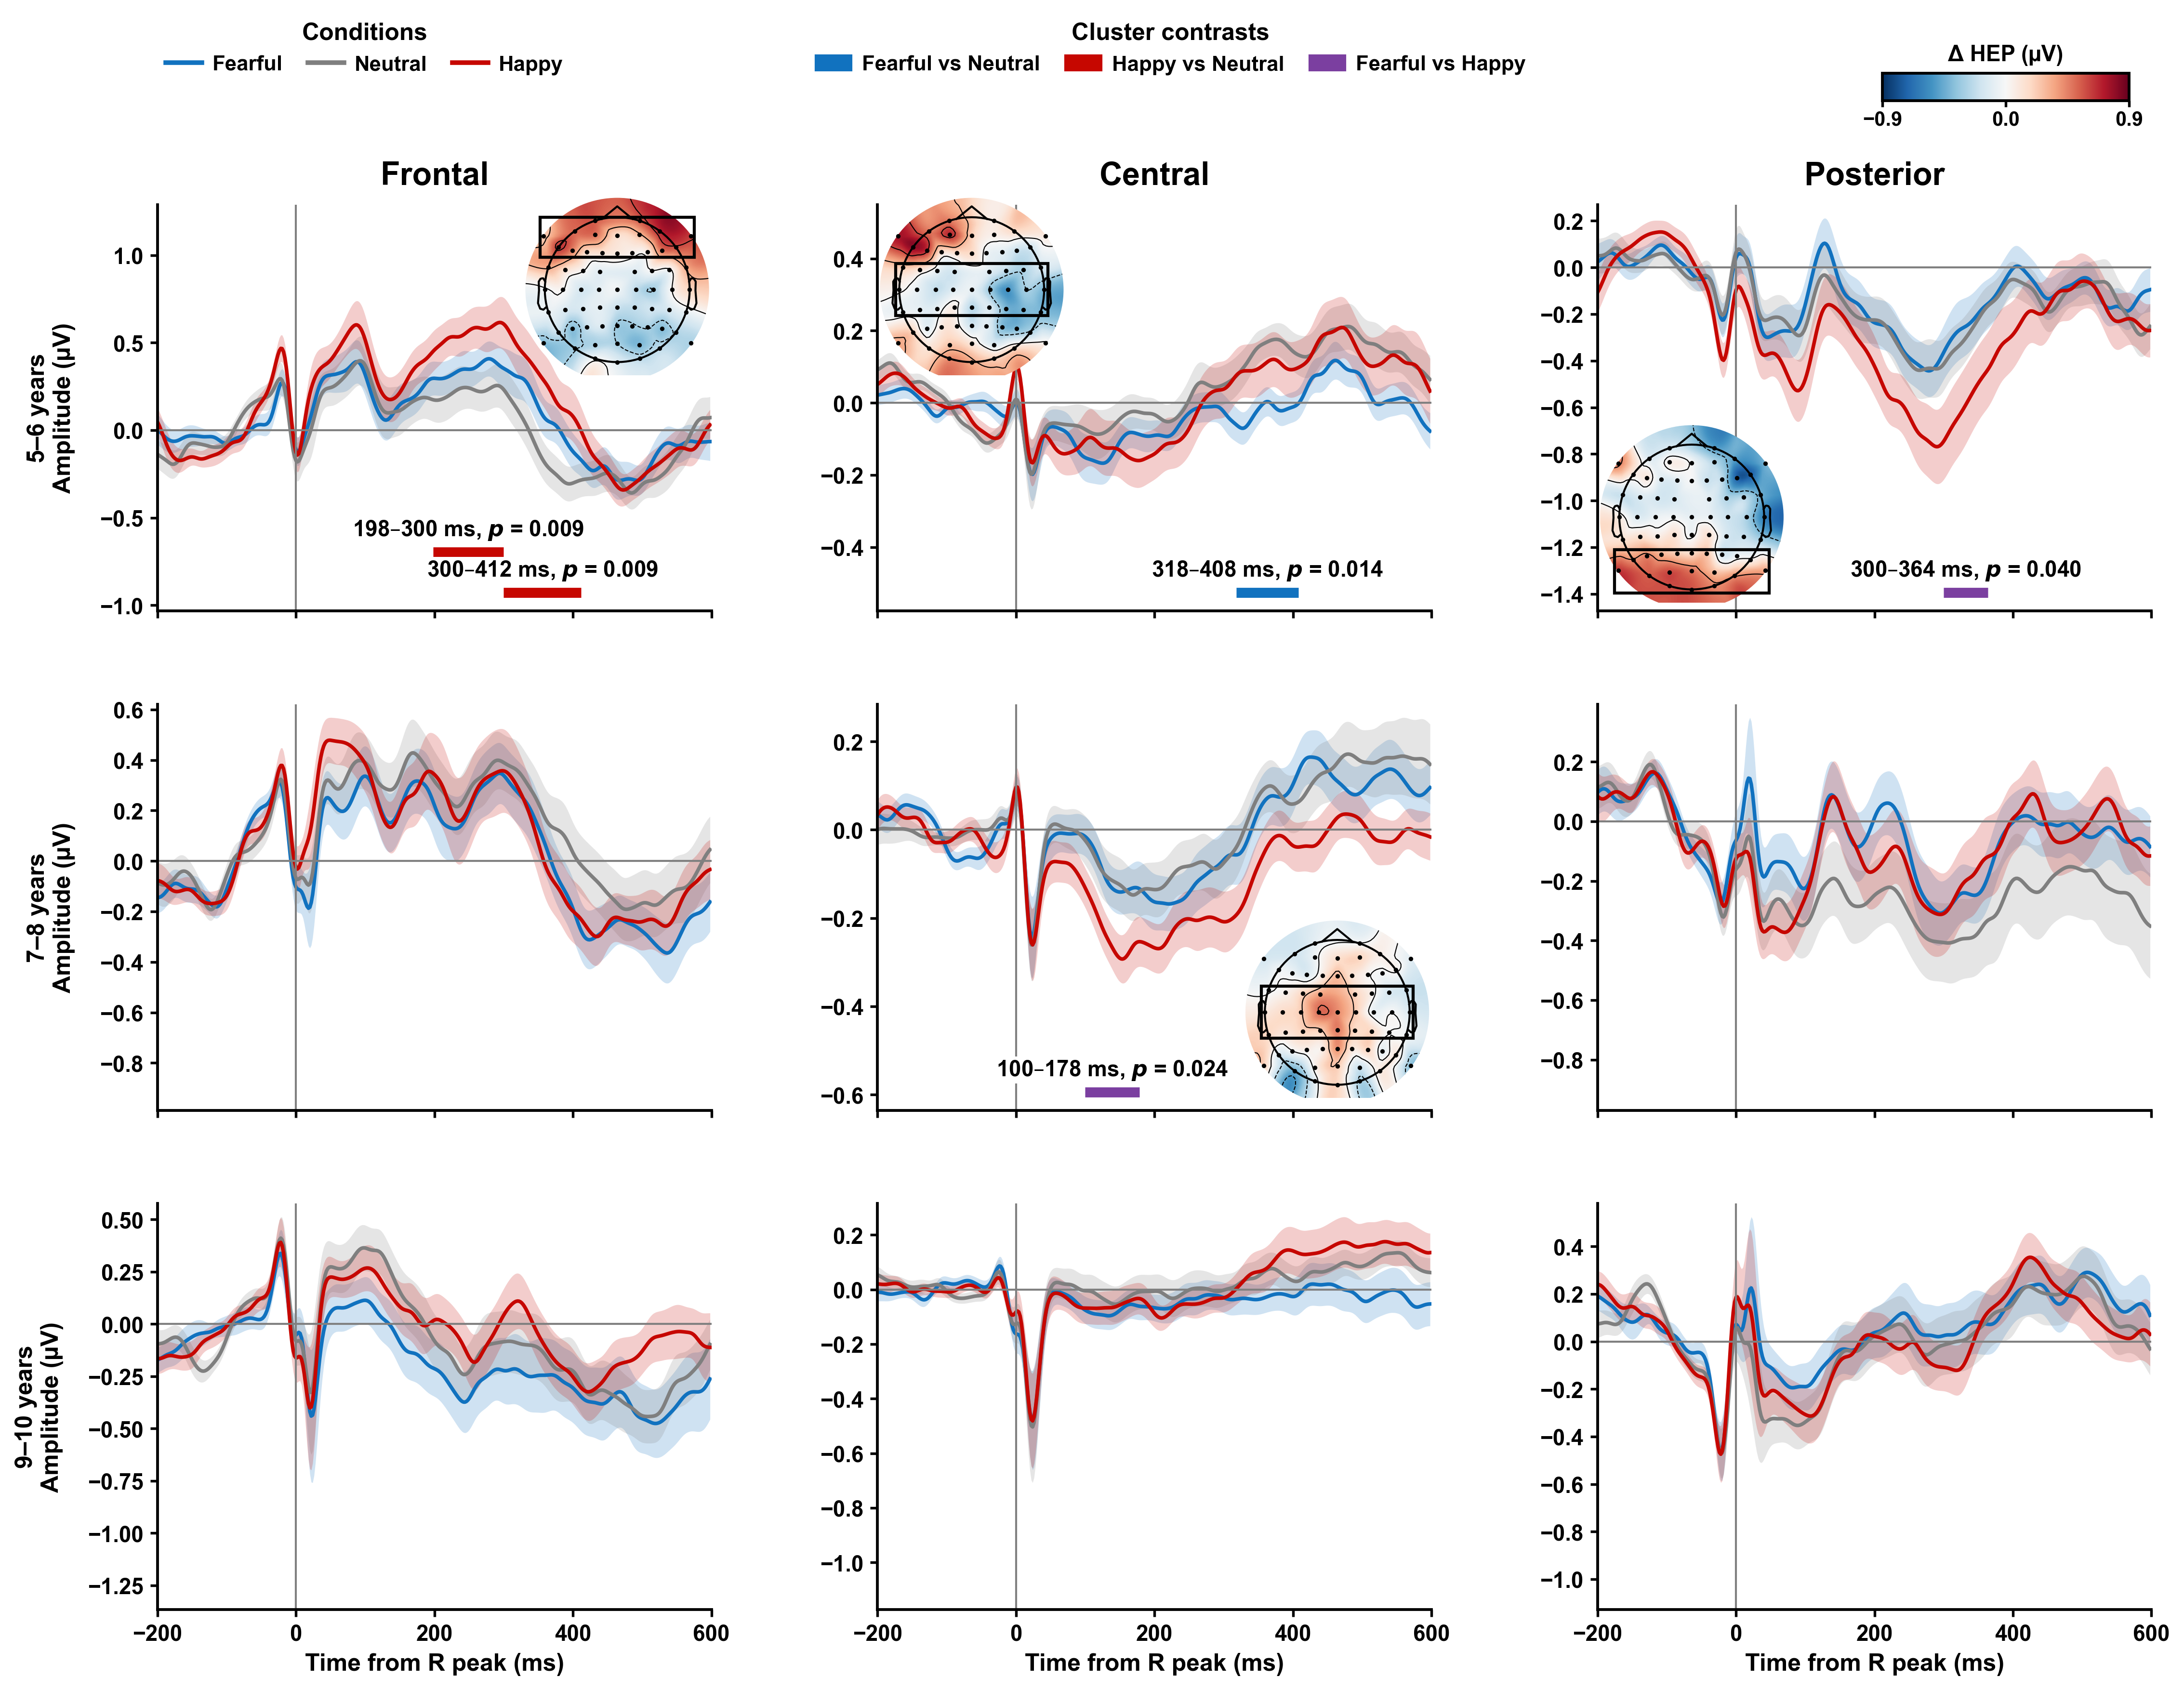

Table S3: results/SI
Figure 3: results/Main/Figure_3_hep.png
Run log: 04_HEP/logs/20261030_224641.log


In [15]:
if not COHORT_READY:
    print("Skipped: cohort analysis was not selected or validated in step 3.")
else:
    with LOG.step("Figure 3"):
        waveform_file = FIGURE_DIR / "Figure_3_waveforms.png"
        if not cache_policy.use_cached_results(
            [waveform_file], recompute=RECOMPUTE or "waveforms" in UPDATED_STEPS,
            inputs=[PATHS.participants, PATHS.roi, PATHS.clusters,
                    HEP / "plotting/plot_hep_waveforms.py", HEP / "config/hep_config.py"],
            label="HEP waveform figure", log=LOG,
        ):
            with mpl.rc_context(mpl.rcParamsDefault):
                waveform_file = draw_waveforms(PATHS)
            UPDATED_STEPS.discard("waveforms")
        scalp_files = scalp_plots.figure_paths(PATHS)
        if not cache_policy.use_cached_results(
            [*scalp_files, TOPO_DIR / "temporal_cluster_map_manifest_final.json"],
            recompute=RECOMPUTE or "scalp figures" in UPDATED_STEPS,
            inputs=[TOPO_DIR / "temporal_cluster_map_inputs.npz",
                    HEP / "plotting/plot_hep_cluster_topographies.py", HEP / "config/hep_config.py"],
            label="HEP scalp figures", log=LOG,
        ):
            with mpl.rc_context(mpl.rcParamsDefault):
                scalp_files = scalp_plots.plot_topographies(PATHS)
            UPDATED_STEPS.discard("scalp figures")
        complete_file = FIGURE_DIR / "Figure_3_hep.png"
        if not cache_policy.use_cached_results(
            [complete_file], recompute=RECOMPUTE,
            inputs=[PATHS.participants, PATHS.roi, PATHS.clusters,
                    TOPO_DIR / "temporal_cluster_map_inputs.npz",
                    HEP / "plotting/plot_figure_3_hep.py",
                    HEP / "plotting/plot_hep_waveforms.py",
                    HEP / "plotting/plot_hep_cluster_topographies.py",
                    HEP / "config/hep_config.py"],
            label="Complete Figure 3", log=LOG,
        ):
            complete_file = draw_figure_3(PATHS)
        display(Image(filename=str(complete_file), width=1100))
        LOG.write(f"Complete Figure 3: {complete_file}")

    print("Table S3:", LOG.display(TABLE_DIR))
    print("Figure 3:", LOG.display(complete_file))
    print("Run log:", LOG.display(LOG.path))


## Further manuscript analyses

The analysis order is **eliciting → correlation → HEP → dBHI**.

The [dBHI notebook](../05_dBHI/run_dbhi.ipynb) examines directional brain–heart
coupling, age prediction and movie-intensity contrasts, producing Figures 4–5,
Figures S3–S7 and Tables S4–S6. It uses its own cohort inputs and saved model data;
the HEP outputs above are not required for that analysis.
